In [179]:
import torch
from torch import optim
import matplotlib.pyplot as plt

In [180]:
def my_muon(W, lr):
    lr_scale = max(1, W.shape[0] / W.shape[1]) ** 0.5
    return optim.Muon(
        [W], lr=lr / lr_scale,
        momentum=0.0, nesterov=False, weight_decay=0.0,
        ns_coefficients=(1.5, -0.5, 0.0), ns_steps=10,
        adjust_lr_fn="original",
    )

In [181]:
def f(X):
    v = X.flatten()
    M = torch.diag(torch.ones(len(v)))
    M[2, 2] = 100
    return 0.5 * torch.dot(v, M @ v)

SGD final value: 2.486384868621826
Spectral final value: 0.5680201053619385
Adam final value: 0.0008028402808122337


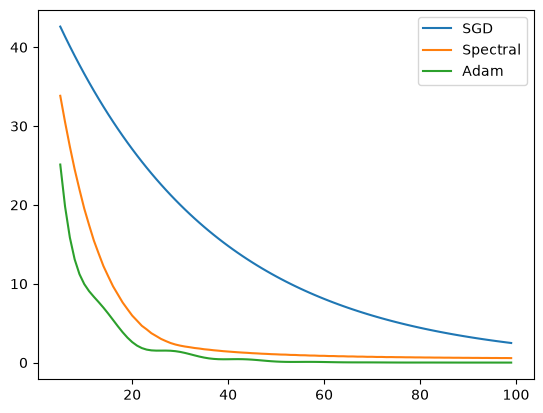

In [182]:
torch.manual_seed(123)
X1 = torch.randn(10, 10, requires_grad=True)
X2 = torch.randn(10, 10, requires_grad=True)
X3 = torch.randn(10, 10, requires_grad=True)

optimizer1 = optim.SGD([X1], lr=0.015)
optimizer2 = my_muon(X2, lr=0.2)
optimizer3 = optim.Adam([X3], lr=0.1)

ys1 = []
ys2 = []
ys3 = []
epoch = 100
for i in range(epoch):
    y = f(X1)
    ys1.append(y.item())

    optimizer1.zero_grad()
    y.backward()
    optimizer1.step()

    y = f(X2)
    ys2.append(y.item())

    optimizer2.zero_grad()
    y.backward()
    optimizer2.step()

    y = f(X3)
    ys3.append(y.item())

    optimizer3.zero_grad()
    y.backward()
    optimizer3.step()

print(f"SGD final value: {ys1[-1]}")
print(f"Spectral final value: {ys2[-1]}")
print(f"Adam final value: {ys3[-1]}")

plt.plot(range(5, epoch), ys1[5:], label='SGD')
plt.plot(range(5, epoch), ys2[5:], label='Spectral')
plt.plot(range(5, epoch), ys3[5:], label='Adam')
plt.legend()
plt.show()